# 02. 环境 GWAS

本 notebook 验证 31 个变量的 environmental GWAS，生成关联诊断，使用 MAGMA 将变异信号汇总到基因，并整合 flowering-time 和 cis-eQTL contexts 进行解释。

## 1. 高粱Landraces的群体和环境

In [1]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

project_dir = os.getcwd()
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'

landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
landrace_metadata_df = pd.read_csv(landrace_metadata_csv)
landrace_metadata_df

,ISnum,PInumber,LIB,Sample,WASAP,PlantName,Germplasm,BotanicalType,Latitude,Longitude,...,bio17,bio19,alt,NTO,CLYPPT,annualPET,TPH,topoWet,PlotBotanicalType,min_dist_to_striga
0,NaN,NaN,IZII,Ni205_177,Ni205,NaN,Landrace,Durra-caudatum,13.232833,8.229278,...,0,0,460.0,373.0,6.0,2017.839966,93.0,13.02,Durra-caudatum,62.236593
1,NaN,NaN,IZIY,Ni295_302,Ni295,El Dan Mato,Landrace,Durra-caudatum,13.123722,7.008417,...,0,0,411.0,368.0,8.0,1994.109985,122.0,12.96,Durra-caudatum,22.765923
2,NaN,NaN,IZIX,Ni293_172,Ni293,Ja Dawa,Landrace,Durra-caudatum,13.024194,7.046028,...,0,0,431.0,412.0,9.0,1982.750000,107.0,12.64,Durra-caudatum,23.155054
3,NaN,NaN,IZJH,Sen053_041,Sn053,Diériker Ndélé,Landrace,Guinea,15.786164,-16.523998,...,7,46,8.0,626.0,18.0,1601.599976,231.0,13.84,Guinea,25.733178
4,NaN,NaN,IZIP,Ni224_310,Ni224,Ja Dawa,Landrace,Durra-caudatum,13.247722,7.736417,...,0,0,428.0,424.0,9.0,1997.520020,96.0,12.95,Durra-caudatum,57.367592
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
438,IS9524,PI563289,IZKC,PI563289,NaN,IS9524,Cultivated,Kafir-durra,-25.746111,28.188056,...,173,256,1335.0,1121.0,27.0,1541.000000,764.0,11.27,Kafir-durra,1131.597982
439,IS9883,PI571271,IPEJ,PI571271,NaN,IS9883,Landrace,Caudatum,11.189999,24.149999,...,0,0,559.0,551.0,36.0,2213.679932,120.0,14.38,Caudatum,198.525796
440,IS9885,PI571273,IXPG,PI571273,NaN,IS9885,Landrace,Caudatum,6.480000,29.420000,...,135,5469,479.0,665.0,27.0,1959.829956,245.0,13.51,Caudatum,209.075913
441,IS9911,PI571292,IPEK,PI571292,NaN,IS9911,Landrace,Caudatum,11.016667,29.716667,...,2,4130,513.0,744.0,40.0,2091.260010,276.0,12.11,Caudatum,1.068439


### 1.1 Landraces群体的亲缘关系

绘制 landraces 的地理分布图，使用不同颜色表示不同的 botanical group

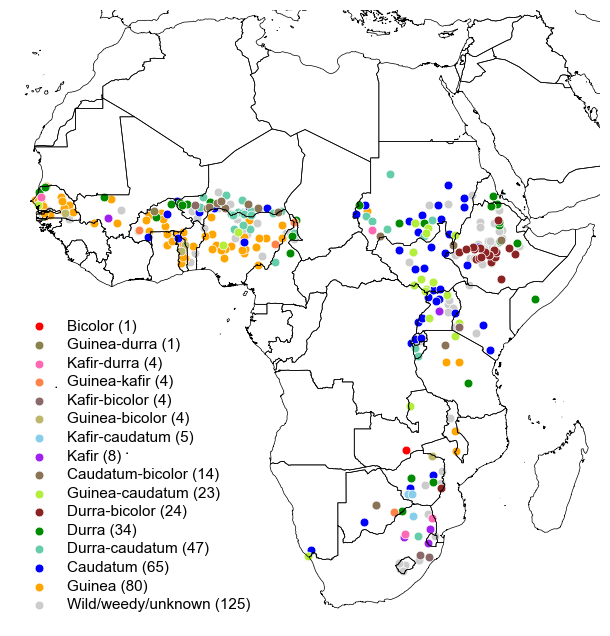

In [ ]:
from src.env_vars import landraces_botanical_map_plotter
world_map_shp = f'{source_dir}/natural_earth/ne_10m_admin_0_countries/ne_10m_admin_0_countries.shp'
save_fig_path = f'{results_dir}/landraces_botanical_map.figS1.pdf'
landraces_botanical_map_plotter(landrace_metadata_df, save_fig_path, world_map_shp)

绘制 landraces 的亲缘关系树图

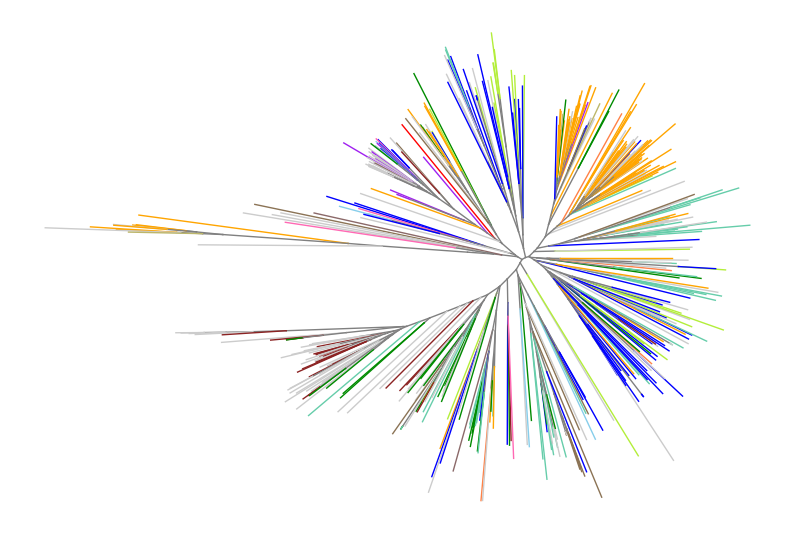

In [ ]:
from src.env_vars import nj_tree_plotter
from src.utils import have_file

snp_pruned_vcf_file = f'{source_dir}/landraces_snp_pruned.win15000.miss0.5.maf0.01.het0.01.rq0.5.vcf.gz'
nj_prefix = f'{results_dir}/landraces_snp_pruned.win15000.miss0.5.maf0.01.het0.01.rq0.5'
nj_tree_file = f'{nj_prefix}.ibs_dist.nj.tree'

if not have_file(nj_tree_file):
    from src.tree import get_ibs_nj_tree_from_snp_pruned_vcf
    get_ibs_nj_tree_from_snp_pruned_vcf(snp_pruned_vcf_file, nj_prefix)

save_fig_path = f'{results_dir}/landraces_nj_tree.figS1.pdf'
nj_tree_plotter(nj_tree_file, landrace_metadata_df, save_fig_path=save_fig_path)

### 1.2 Landraces群体指标

#### 1.2.1 连锁不平衡 decay

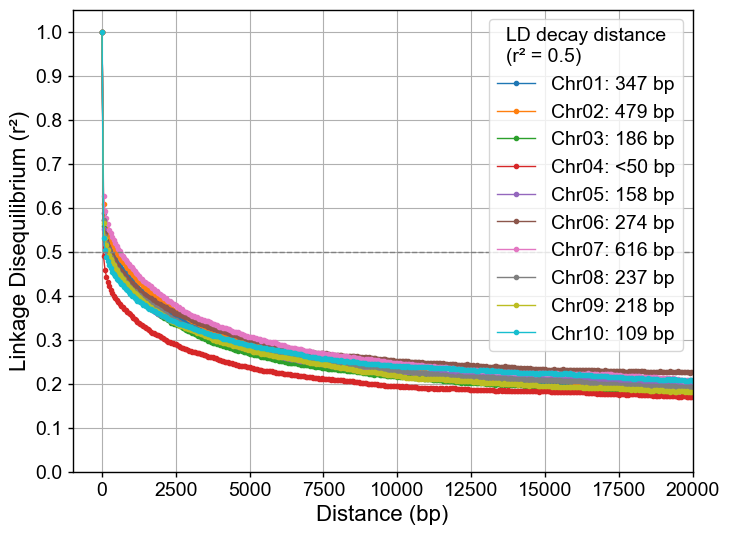

Decay cache: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz.ld_decay.csv.gz
Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz.ld_decay.pdf


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from src.ld import calculate_ld_decay, plot_ld_decay

# Paths are interpreted by the remote notebook kernel.
ld_vcf_file = f'{results_dir}/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz'
ld_stat_file = Path(f'{ld_vcf_file}.var_stat.h5')

# Match the old decay analysis's site filters and 100 bp bins.
ld_max_distance = 20000
ld_bin_size = 50
ld_half_value = 0.5
ld_pool_num = 40
ld_force_recompute = False

ld_tag = f"{ld_vcf_file}.ld_decay"
ld_decay_cache = f'{ld_tag}.csv.gz'
ld_figure_file = f'{ld_tag}.pdf'

if ld_force_recompute or not Path(ld_decay_cache).is_file():
    with pd.HDFStore(ld_stat_file, mode="r") as ld_store:
        ld_sites = pd.concat([ld_store[key] for key in ld_store.keys()], ignore_index=True)
    # Stable chromosome order gives the same tab10 color order as the old plot.
    ld_sites = ld_sites.sort_values(["CHROM", "POS"]).reset_index(drop=True)
    ld_decay_df = calculate_ld_decay(
        ld_sites, str(ld_vcf_file), max_decay_size=ld_max_distance,
        curve_bin_size=ld_bin_size,
        pool_num=ld_pool_num,
    )
    ld_decay_df.to_csv(ld_decay_cache, index=False, compression='gzip')
else:
    ld_decay_df = pd.read_csv(ld_decay_cache, compression='gzip')

ld_fig, ld_ax, ld_half_dist_df = plot_ld_decay(
    ld_decay_df, half_ld_value=ld_half_value, figsize=(8, 6),
    xlim=(-500, ld_max_distance), save_fig_path=ld_figure_file,
)
plt.show()
print(f"Decay cache: {ld_decay_cache}")
print(f"Figure: {ld_figure_file}")

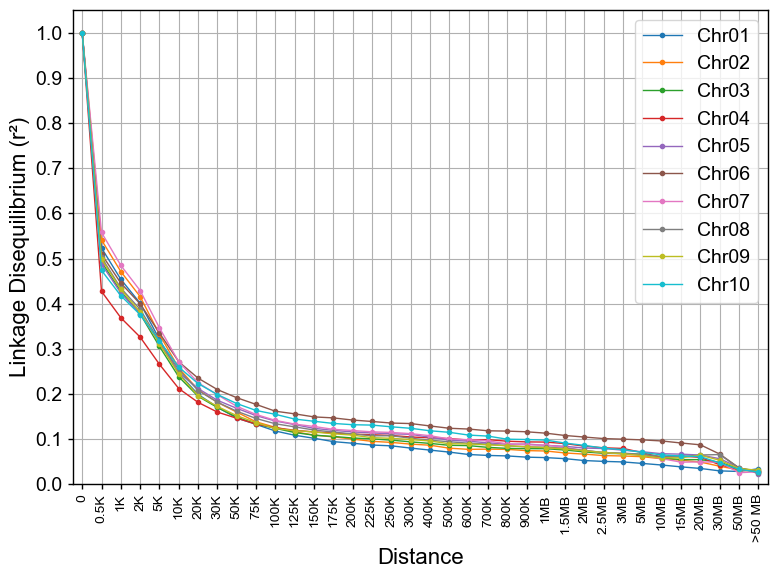

Decay cache: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.csv.gz
Figure: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz.multiscale_ld_decay.pdf


In [ ]:
from pathlib import Path
import matplotlib.pyplot as plt
from src.ld import (
    calculate_multiscale_ld_decay,
    plot_multiscale_ld_decay,
    summarize_ld_decay_thresholds,
    summarize_multiscale_ld_overflow,
)

ld_min_maf = 0.05
ld_max_het = 0.05
ld_vcf_file = f'{results_dir}/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz'
ld_stat_file = Path(f'{ld_vcf_file}.var_stat.h5')
ld_pool_num = 40

# Existing CSV: load it directly; otherwise run/save the computation.
multiscale_ld_csv = f"{ld_vcf_file}.multiscale_ld_decay.csv.gz"
if Path(multiscale_ld_csv).is_file():
    multiscale_ld_df = pd.read_csv(multiscale_ld_csv)
else:
    multiscale_ld_df = calculate_multiscale_ld_decay(
        ld_stat_file, ld_vcf_file, min_maf=ld_min_maf, max_het=ld_max_het,
        full_distance=200_000, max_pairs_per_bin=50_000, random_seed=42,
        pool_num=ld_pool_num, silence=False, cache_file=multiscale_ld_csv,
    )
multiscale_ld_fig, multiscale_ld_ax = plot_multiscale_ld_decay(
    multiscale_ld_df, save_fig_path=f"{ld_vcf_file}.multiscale_ld_decay.pdf", figsize=(8, 6)
)
plt.show()
multiscale_ld_thresholds = summarize_ld_decay_thresholds(multiscale_ld_df)
multiscale_ld_overflow_qc = summarize_multiscale_ld_overflow(multiscale_ld_df)
print(f"Decay cache: {multiscale_ld_csv}")
print(f"Figure: {ld_vcf_file}.multiscale_ld_decay.pdf")

#### 1.2.2 Genome landscape

The cell below prepares all landscape sources and calls `build_genome_tracks` / `plot_genome_tracks`. DAF is loaded from `landraces_DAF.csv.gz` when present; otherwise it is calculated using landraces as the target and wilds as the outgroup (ancestral frequency threshold 0.9), then cached. Cache reuse skips sample-list loading, combined-VCF preparation and DAF calculation. The window DAF mean uses only biallelic SNPs with DAF ≥ 0.05; qualifying sites are counted in DAF_SITE_COUNT and empty means remain NaN. The DAF track follows MAF and is included in the plot-data CSV.gz. The cache remains site-level; filtering and window aggregation happen in `build_genome_tracks`, so the same cache can be reused at different resolutions.

Repeat density reads the repeat GFF similarity intervals, merges overlaps and computes covered-bp fractions in base windows. Plotting-bin repeat density is computed directly from the repeat GFF union over each full plotting bin, including bases without SNPs; base-window repeat fractions are not averaged. Repeat density follows Gene density and is exported as REPEAT_FRACTION in CSV.gz.


## 4. Genome window contexts (500 bp)

Build `data/results/genome_windows_contexts.b500.h5` from position 1 to the end of every reference sequence using contiguous, 1-based inclusive 500 bp bins (1–500, 501–1000, 1001–1500, …). The final bin is truncated at the reference length. Each context column is the fraction of window bases covered by the union of its intervals, including bases without variants; overlaps count once within each context. Contexts may overlap with one another.

Include gene/neighborhood and gene-structure intervals, TE, other intergenic regions, ACR, UMR, pi classes and recombination classes. Exclude variant-ID, coding-consequence, phyloP and MAF labels. Reuse the existing pi methods and cache their interval statistics separately. BED coordinates default to the existing site annotation convention (1-based inclusive); use `bed_zero_based=True` if the supplied files are standard 0-based half-open BED. Reference lengths require the existing FASTA `.fai`.

`REPEAT_FRACTION` includes all repeat `similarity` annotations in the repeat GFF, including classes outside TE. Existing window tables missing this column are updated without recalculating other contexts.


## 4. 基因组窗口 contexts（500 bp）

从每条参考序列的第 1 bp 到末尾，按连续的 1-based 闭区间 500 bp 分箱（1–500、501–1000、1001–1500、……），构建 `data/results/genome_windows_contexts.b500.h5`。末尾窗口截断至参考序列长度。每个 context 列表示其区间并集覆盖的碱基数占窗口实际长度的比例，包含没有变异的碱基；同一 context 内的重叠碱基只计一次，不同 contexts 可以重叠。

纳入基因及邻域、基因结构、TE、其他基因间区、ACR、UMR、π 分类及重组率分类。排除位点 ID、编码后果、phyloP 及 MAF 标签。复用现有 π 计算方法，并单独缓存其区间统计。BED 默认沿用现有位点注释的 1-based 闭区间约定；若输入为标准 0-based 半开 BED，请设置 `bed_zero_based=True`。参考序列长度需要已有 FASTA `.fai`。

`REPEAT_FRACTION` 纳入 repeat GFF 中全部 repeat `similarity` 注释，包括 TE 以外的类别。已有窗口表缺少此列时会补充并保存，无需重新计算其他 contexts。


In [ ]:
from src.contexts import get_genome_windows_contexts, get_window_repeat_contexts, get_pi_statistics, get_genome_allele_statistics

window_size = 500
genome_windows_contexts_h5 = f'{results_dir}/genome_windows_contexts.b{window_size}.h5'
ref_genome_fa = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
ref_gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
ref_repeat_gff_file = f'{source_dir}/Sbicolor_730_v5.1.repeatmasked_assembly_v5.0.gff3.gz'
vcf_file = f'{results_dir}/landraces.vcf.gz'
recombination_file = f'{source_dir}/avg_cM_genomewide_NAM_population.csv.gz'
bed_files = {name: f'{source_dir}/{name}s.v5.bed.gz' for name in ['ACR', 'UMR']}

if not have_file(genome_windows_contexts_h5):
    window_contexts = {}
    for region, suffix in [('genic_15kb', ''), ('genome', '_genome')]:
        pi_statistics_h5 = f'{results_dir}/pi_statistics.{region}.b{window_size}.min_snp3.h5'
        if not have_file(pi_statistics_h5):
            if region == 'genic_15kb':
                pi_df = get_pi_statistics(ref_gff_file, ref_genome_fa, vcf_file,
                                         window_size=window_size, gene_flank_size=15000, min_snp_count=3)
            else:
                pi_df = get_genome_allele_statistics(ref_genome_fa, vcf_file, recombination_file,
                                                   window_size=window_size, min_snp_count=3, chunk_size=1_000_000)
            pi_df.to_hdf(pi_statistics_h5, key='df')
        else:
            pi_df = pd.read_hdf(pi_statistics_h5, key='df')
        low_threshold = pi_df['PI'].quantile(0.25)
        high_threshold = pi_df['PI'].quantile(0.75)
        window_contexts[f'low_pi{suffix}'] = pi_df[pi_df['PI'] < low_threshold]
        window_contexts[f'med_pi{suffix}'] = pi_df[(pi_df['PI'] >= low_threshold) & (pi_df['PI'] < high_threshold)]
        window_contexts[f'high_pi{suffix}'] = pi_df[pi_df['PI'] >= high_threshold]

    genome_windows_contexts_df = get_genome_windows_contexts(
        ref_genome_fa, ref_gff_file, ref_repeat_gff_file,
        bed_files=bed_files, window_contexts=window_contexts,
        recombination_file=recombination_file, window_size=window_size, bed_zero_based=False)
    genome_windows_contexts_df.to_hdf(genome_windows_contexts_h5, key='df')
else:
    genome_windows_contexts_df = pd.read_hdf(genome_windows_contexts_h5, key='df')

if 'REPEAT_FRACTION' not in genome_windows_contexts_df.columns:
    genome_windows_contexts_df = get_window_repeat_contexts(genome_windows_contexts_df, ref_repeat_gff_file)
    genome_windows_contexts_df.to_hdf(genome_windows_contexts_h5, key='df')

print(genome_windows_contexts_h5)
genome_windows_contexts_df


Using allele statistics cache: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_allele_statistics.csv.gz
Using DAF cache: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_DAF.csv.gz


Calculating window MAF: 100%|██████████| 149/149 [02:48<00:00,  1.13s/chunk]


MAF excluded 0 non-biallelic and 0 fully missing sites on plotted chromosomes.


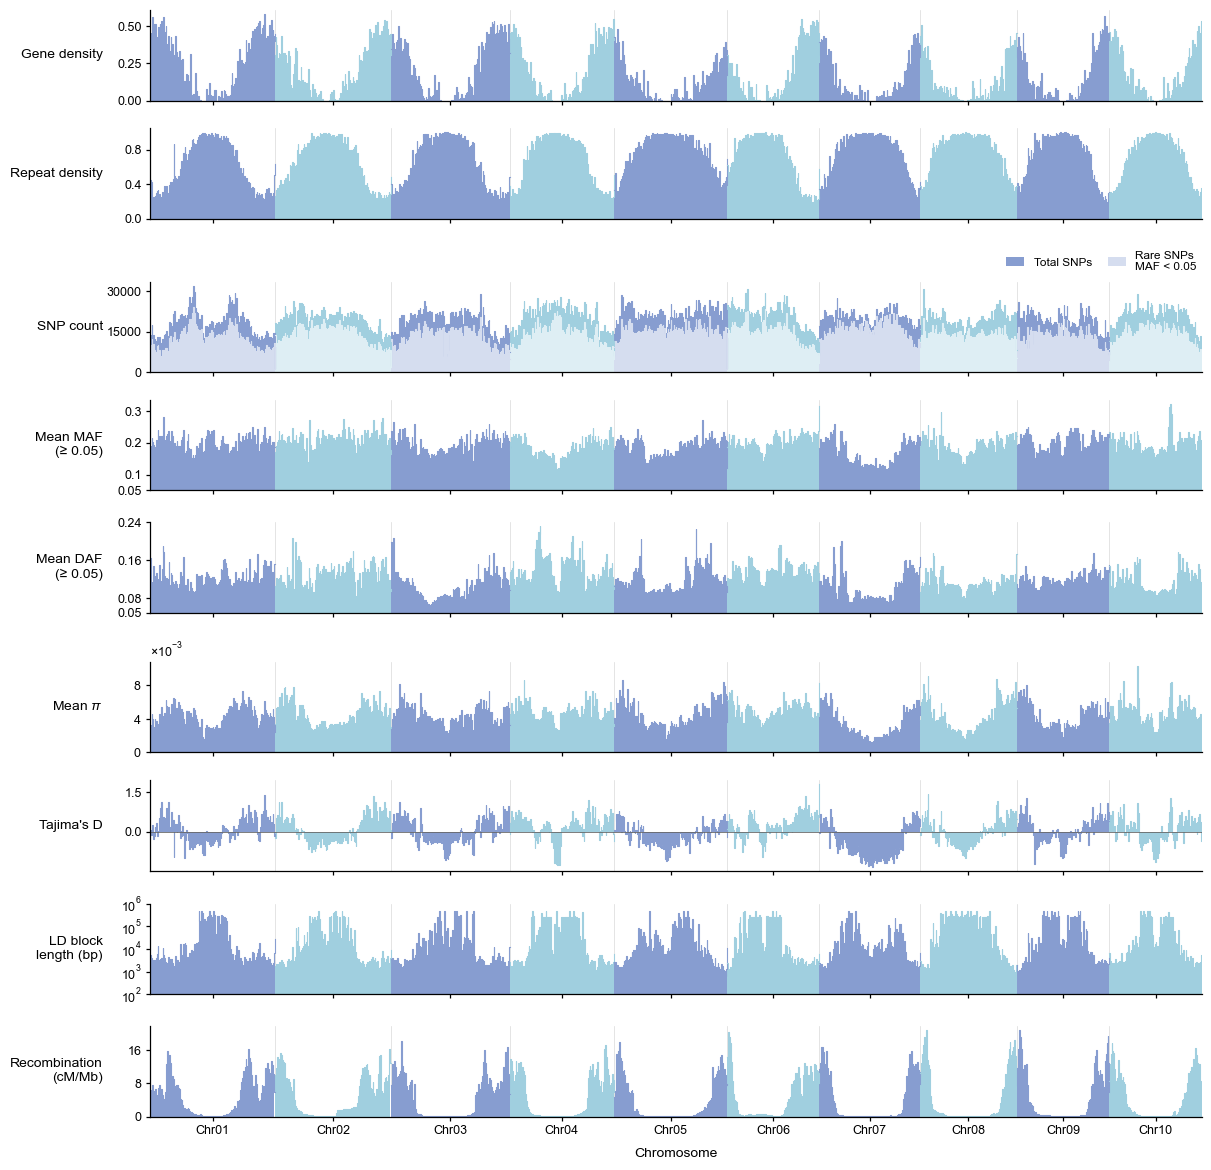

pdf: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_500000bp.pdf
png: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_500000bp.png
csv: /lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/landraces_genome_tracks_500000bp.csv.gz


In [2]:
from pathlib import Path
from src.vcf import extract_samples_vcf
import pandas as pd
import matplotlib.pyplot as plt

from src.contexts import (
    get_genome_allele_statistics,
    calculate_DAF,
    build_genome_tracks,
    plot_genome_tracks,
)

# Load data sources and output paths
ld_unfiltered_vcf_file = f'{source_dir}/landraces.vcf.gz'
ref_genome_fa = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
ref_gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'
ref_repeat_gff_file = f'{source_dir}/Sbicolor_730_v5.1.repeatmasked_assembly_v5.0.gff3.gz'
recombination_file = f'{source_dir}/avg_cM_genomewide_NAM_population.csv.gz'
allele_stat_csv = f'{results_dir}/landraces_allele_statistics.csv.gz'
landraces_DAF_csv = f'{results_dir}/landraces_DAF.csv.gz'
landraces_metadata_file = f'{source_dir}/landraces_metadata.csv'
wilds_metadata_file = f'{source_dir}/wilds_metadata.csv'
wgs_vcf_file = f'{source_dir}/Sorghum_WGS.vcf.gz'
landraces_and_wilds_vcf_file = f'{results_dir}/landraces_and_wilds.vcf.gz'
plink_blocks_result_file = (
    f'{results_dir}/landraces_qc_miss0.5_maf0.05_het0.05.plink_blocks/'
    'landraces.maf0.05.biallelic.blocks_max500kb.project_chr.blocks.det'
)

# Set parameters: base statistics resolution, plotting resolution, MAF parallelism, and display style
allele_window_size = 500  # bp，仅缓存不存在时用于基础统计
allele_min_snp_count = 3
allele_chunk_size = 1_000_000
allele_ld_min_maf = 0.05
min_allele_count = 3 # 最小等位基因计数，小于这个数的位点将被忽略
track_window_size = 500_000  # bp，最终绘图窗口
rare_maf_threshold = 0.05  # 稀有：MAF < 0.05；平均 MAF：MAF >= 0.05
min_daf = 0.05  # DAF 窗口均值仅纳入 DAF >= 0.05 的 SNP
min_ancestral_allele_frequency = 0.9
maf_n_jobs = 8  # 不超过分配的 CPU 核数；1 为串行
maf_chunk_size = 5_000_000  # bp，自动对齐绘图窗口
track_output_prefix = Path(f'{results_dir}/landraces_genome_tracks_{track_window_size}bp')

# 读取 LD blocks 与基础统计缓存；缓存不存在时才计算并保存
ld_blocks = pd.read_csv(plink_blocks_result_file, sep=r'\s+', engine='python')
# 读取allele统计信息
if not Path(allele_stat_csv).is_file():
    print(f'Allele statistics cache not found, calculating and saving to: {allele_stat_csv}')
    allele_stat_df = get_genome_allele_statistics(
        ref_genome_fa,
        ld_unfiltered_vcf_file,
        recombination_file,
        window_size=allele_window_size,
        min_snp_count=allele_min_snp_count,
        chunk_size=allele_chunk_size,
        ld_min_maf=allele_ld_min_maf,
        mac=min_allele_count,
        ref_repeat_gff_file=ref_repeat_gff_file,
    )
    Path(allele_stat_csv).parent.mkdir(parents=True, exist_ok=True)
    allele_stat_df.to_csv(allele_stat_csv, index=False, compression='gzip')
else:
    print(f'Using allele statistics cache: {allele_stat_csv}')
    allele_stat_df = pd.read_csv(allele_stat_csv, compression='gzip')

# DAF 缓存存在时直接读取，跳过样品读取、联合 VCF 准备及 DAF 重算
if Path(landraces_DAF_csv).is_file():
    landraces_DAF_df = pd.read_csv(landraces_DAF_csv, compression='gzip', dtype={'CHROM': str})
    print(f'Using DAF cache: {landraces_DAF_csv}')
else:
    landraces_metadata_df = pd.read_csv(landraces_metadata_file)
    wilds_metadata_df = pd.read_csv(wilds_metadata_file)
    landraces_sample_list = landraces_metadata_df['LIB'].tolist()
    wilds_sample_list = wilds_metadata_df['LIB'].tolist()
    if not Path(landraces_and_wilds_vcf_file).is_file():
        Path(landraces_and_wilds_vcf_file).parent.mkdir(parents=True, exist_ok=True)
        extract_samples_vcf(
            wgs_vcf_file, landraces_sample_list + wilds_sample_list,
            landraces_and_wilds_vcf_file,
        )
    landraces_DAF_df = calculate_DAF(
        landraces_and_wilds_vcf_file,
        landraces_sample_list,
        wilds_sample_list,
        min_ancestral_allele_frequency=min_ancestral_allele_frequency,
        keep_nan=False,
    )
    Path(landraces_DAF_csv).parent.mkdir(parents=True, exist_ok=True)
    landraces_DAF_df.to_csv(landraces_DAF_csv, index=False, compression='gzip')
    print(f'Saved DAF cache: {landraces_DAF_csv}')

# 5. 汇总绘图窗口：基因/重复密度、总/稀有 SNP、MAF、DAF、π、D、LD、重组率
track_df = build_genome_tracks(
    allele_stat_df=allele_stat_df,
    ld_blocks=ld_blocks,
    vcf_file=ld_unfiltered_vcf_file,
    gff_file=ref_gff_file,
    ref_genome_fa=ref_genome_fa,
    window_size=track_window_size,
    rare_maf_threshold=rare_maf_threshold,
    n_jobs=maf_n_jobs,
    chunk_size=maf_chunk_size,
    daf_df=landraces_DAF_df,
    min_daf=min_daf,
    ref_repeat_gff_file=ref_repeat_gff_file,
)

# 6. 绘图并保存 PDF、PNG、CSV.gz；调整样式时只需重跑本段，复用 track_df
track_plot = plot_genome_tracks(
    track_df,
    output_prefix=track_output_prefix,
    title=None,
    rare_maf_threshold=rare_maf_threshold,
    maf_ymin=0.05,
    ld_ylim=(1e2, 1e6),
    figsize=(12, 11.7),
    hspace=0.1,
    h_pad=0.1,
    label_fontsize=10,
    tick_fontsize=9,
    title_fontsize=12,
)
track_fig, track_axes = track_plot['figure'], track_plot['axes']
track_plot_df = track_plot['plot_data']
plt.show()
for kind, file_path in track_plot['files'].items():
    print(f'{kind}: {file_path}')

### 1.3 Landraces群体的环境特征

In [ ]:
envir_metadata_csv = f'{source_dir}/envir_metadata.csv'
envir_metadata_df = pd.read_csv(envir_metadata_csv)
envir_metadata_df

,env_id,env_abbr,category,short description,description,source,units,scale,note,Reference DOI
0,bio1,TMA,Temperature,Mean.Tmp.Annual,Annual Mean Temperature,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
1,bio2,TRD,Temperature,Mean.Diurnal.Range,Mean Diurnal Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
2,bio3,ISO,Temperature,Isothermality,Isothermality,CHELSA V2.1,%,NaN,NaN,10.1038/sdata.2017.122
3,bio4,TSE,Temperature,Tmp.Seasonality,Temperature Seasonality,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
4,bio7,TAR,Temperature,Tmp.Annual.Range,Temperature Annual Range,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
5,bio8,TWQ,Temperature,Mean.Tmp.Wet.Q,Mean Temperature of Wettest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
6,bio9,TDQ,Temperature,Mean.Tmp.Dry.Q,Mean Temperature of Driest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
7,bio10,THQ,Temperature,Mean.Tmp.Warm.Q,Mean Temperature of Warmest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
8,bio11,TCQ,Temperature,Mean.Tmp.Cold.Q,Mean Temperature of Coldest Quarter,CHELSA V2.1,°C,100.0,NaN,10.1038/sdata.2017.122
9,bio15,PSE,Precipitation,Prec.Seasonality,Precipitation Seasonality,CHELSA V2.1,mm,10.0,NaN,10.1038/sdata.2017.122


展示landraces所处的环境变量

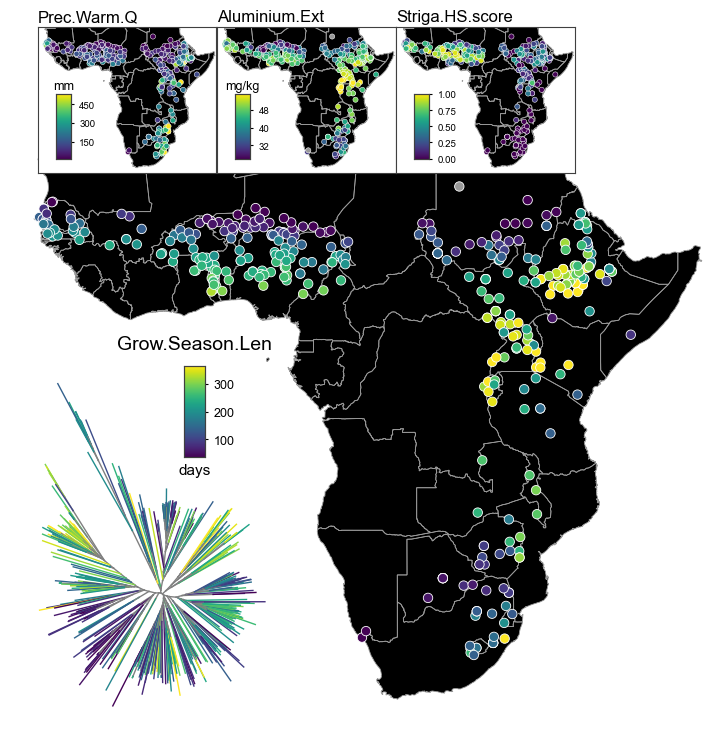

In [ ]:
from src.env_vars import env_vars_map_plotter
main_env = 'gsl'
small_envs = ['bio18', 'al', 'striga']
longitude_limit = (-20, 52)
latitude_limit = (-37, 22)
save_fig_path = f'{results_dir}/landraces_env_vars_map.fig1.pdf'

env_vars_map_plotter(main_env,
                     small_envs,
                     landrace_metadata_df,
                     nj_tree_file,
                     envir_metadata_df,
                     save_fig_path,
                     world_map_shp,
                     longitude_limit=longitude_limit,
                     latitude_limit=latitude_limit)

Redundancy Analysis (RDA): 分析环境变量对基因型的解释能力，计算 RDA1 和 RDA2 的贡献度，并计算调整后的 R2。

Adjusted R-squared: 0.1874


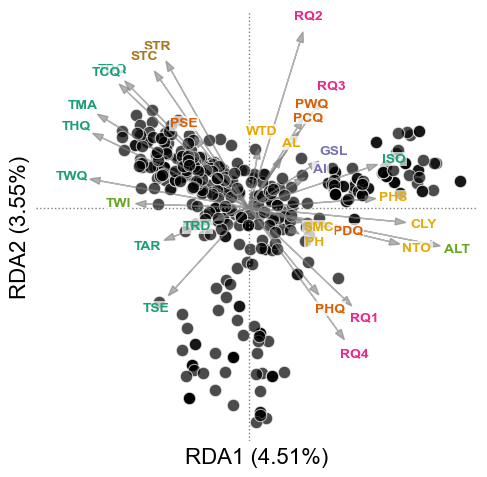

In [ ]:
from src.utils import have_file

rda_output_dir = f'{results_dir}/RDA'
rda_samples_csv = f'{rda_output_dir}/rda_samples.csv'
rda_env_contrib_csv = f'{rda_output_dir}/rda_env_contrib.csv'
rda_explained_csv = f'{rda_output_dir}/rda_explained.csv'

if not have_file(rda_samples_csv) or not have_file(rda_env_contrib_csv) or not have_file(rda_explained_csv):
    from src.env_vars import rda_analysis
    landraces_env_df = landrace_metadata_df[['LIB'] + envir_metadata_df['env_id'].tolist()]
    landraces_env_df.set_index('LIB', inplace=True)
    rda_analysis(vcf=snp_pruned_vcf_file,
                 landraces_env_df=landraces_env_df,
                 kinship_file=f'{nj_prefix}.ibs.matrix',
                 output_dir=rda_output_dir)

rda_samples_df = pd.read_csv(rda_samples_csv, index_col=0)
rda_env_contrib_df = pd.read_csv(rda_env_contrib_csv, index_col=0)
rda_explained_df = pd.read_csv(rda_explained_csv, index_col=0)
r2_adj = rda_explained_df[rda_explained_df['RDA'] == 'R2_adj']['explained_variance'].values[0]
print(f"Adjusted R-squared: {r2_adj:.4f}")

from src.env_vars import plot_rda_biplot
save_fig_path = f'{results_dir}/landraces_env_rda.fig1.pdf'
plot_rda_biplot(rda_samples_df, rda_env_contrib_df, rda_explained_df, envir_metadata_df, save_fig_path)

环境变量间存在多重共线性，可视化其相关性

isolates = ['TPH', 'WTD', 'bio17', 'ph', 'soil_m']
isolated_node_positions after mapping/filter = {'WTD': (0.15000000000000022, 0.48), 'TPH': (0.15000000000000022, -0.24), 'bio17': (0.5500000000000002, 0.48), 'ph': (0.5500000000000002, -0.24), 'soil_m': (0.9500000000000001, 0.48)}


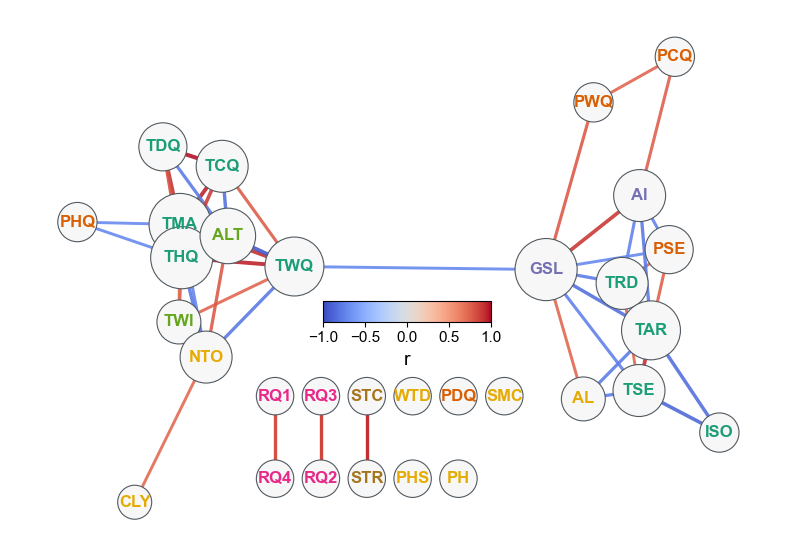

In [ ]:
from src.env_vars import plot_env_corr_network

corr_file = f'{results_dir}/env_correlation_matrix.csv'
save_fig_path = f'{results_dir}/env_network_custom_layout.fig1.pdf'
landraces_env_df = landrace_metadata_df[['LIB'] + envir_metadata_df['env_id'].tolist()]
landraces_env_df.set_index('LIB', inplace=True)
plot_env_corr_network(envir_metadata_df, landraces_env_df, r_threshold=0.7, corr_file=corr_file, save_fig_path=save_fig_path)

## 2. Environmental GWAS

以 landraces 的环境变量为表型，在控制了群体结构的情况下，进行环境 GWAS 分析 （GEMMA 进行线性混合模型分析），在获取位点级别的 p-value 后，使用 MAGMA 将变异信号汇总到基因

In [ ]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

project_dir = os.getcwd()
data_dir = f'{project_dir}/data'
source_dir = f'{data_dir}/source'
results_dir = f'{data_dir}/results'
run_dir = f'{project_dir}/run'

ref_genome_file = f'{source_dir}/Sbicolor_730_v5.0.fa.gz'
ref_gff_file = f'{source_dir}/Sbicolor_730_v5.1.gene_exons.gff3.gz'

landrace_metadata_csv = f'{source_dir}/landraces_metadata.csv'
landrace_metadata_df = pd.read_csv(landrace_metadata_csv)

envir_metadata_csv = f'{source_dir}/envir_metadata.csv'
envir_metadata_df = pd.read_csv(envir_metadata_csv)

landraces_vcf_file = f'{results_dir}/landraces_qc_miss0.5_maf0.05_het0.05.vcf.gz'
landraces_cds_vcf_file = f'{results_dir}/landraces_cds_miss0.5_maf0.01_het0.05.vcf.gz'
ibs_matrix_file = f'{results_dir}/landraces_snp_pruned.win15000.miss0.5.maf0.01.het0.01.rq0.5.ibs.matrix'

In [ ]:
from src.utils import have_file, mkdir
from src.gwas import GEMMA_JOB, MAGMA_JOB, plot_gwas_summary_panel
import numpy as np

gwas_dir = f'{results_dir}/gwas'
mkdir(gwas_dir)

envGWAS_job_dict = {}

for env_name in envir_metadata_df['env_id'].tolist():
    env_description = envir_metadata_df[envir_metadata_df['env_id'] == env_name]['description'].values[0]
    print("Processing environment variable:", env_name)
    env_job_dir = f'{gwas_dir}/{env_name}'
    mkdir(env_job_dir)

    # prepare phenotype file
    pheno_file = f'{env_job_dir}/pheno.bimbam'
    lib_id_env_df = landrace_metadata_df.set_index('LIB')[['Latitude', 'Longitude', env_name]]
    
    with open(pheno_file, 'w') as f:
        for i in lib_id_env_df[env_name].to_list():
            if np.isnan(i):
                f.write('NA\n')
            else:
                f.write(str(i) + '\n')

    # build envGWAS jobs
    all_site_gemma_job = GEMMA_JOB(name=env_name, work_dir=env_job_dir, input_vcf_file=landraces_vcf_file, 
                                   phenotype_file=pheno_file, kinship_file=ibs_matrix_file)
    all_site_gemma_job.run()
    gwas_summary_panel_fig_path = f'{env_job_dir}/{env_name}.gemma/{env_name}.gemma.gwas_df_gwas_summary.png'
    if not have_file(gwas_summary_panel_fig_path):
        plot_gwas_summary_panel(all_site_gemma_job.gwas_df_h5, ref_genome_file,
                                threshold_fdr=0.05,
                                bins=50,
                                title=env_description,
                                save=True)

    all_site_magma_job = MAGMA_JOB(name=env_name, work_dir=env_job_dir, input_vcf_file=landraces_vcf_file, 
                                   gff_file=ref_gff_file, site_gwas_df_h5=all_site_gemma_job.gwas_df_h5, phenotype_file=pheno_file)
    all_site_magma_job.run()

    cds_gemma_job = GEMMA_JOB(name=f"{env_name}_cds", work_dir=env_job_dir, input_vcf_file=landraces_cds_vcf_file, 
                            phenotype_file=pheno_file, kinship_file=ibs_matrix_file)
    cds_gemma_job.run()


    envGWAS_job_dict[env_name] = {
        "site": all_site_gemma_job,
        "gene": all_site_magma_job,
        "cds": cds_gemma_job,
    }

Processing environment variable: bio1
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio2
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio3
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio4
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio7
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio8
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environment variable: bio9
GEMMA GWAS result already exists.
MAGMA GWAS result already exists.
GEMMA GWAS result already exists.
Processing environme

可视化GWAS结果

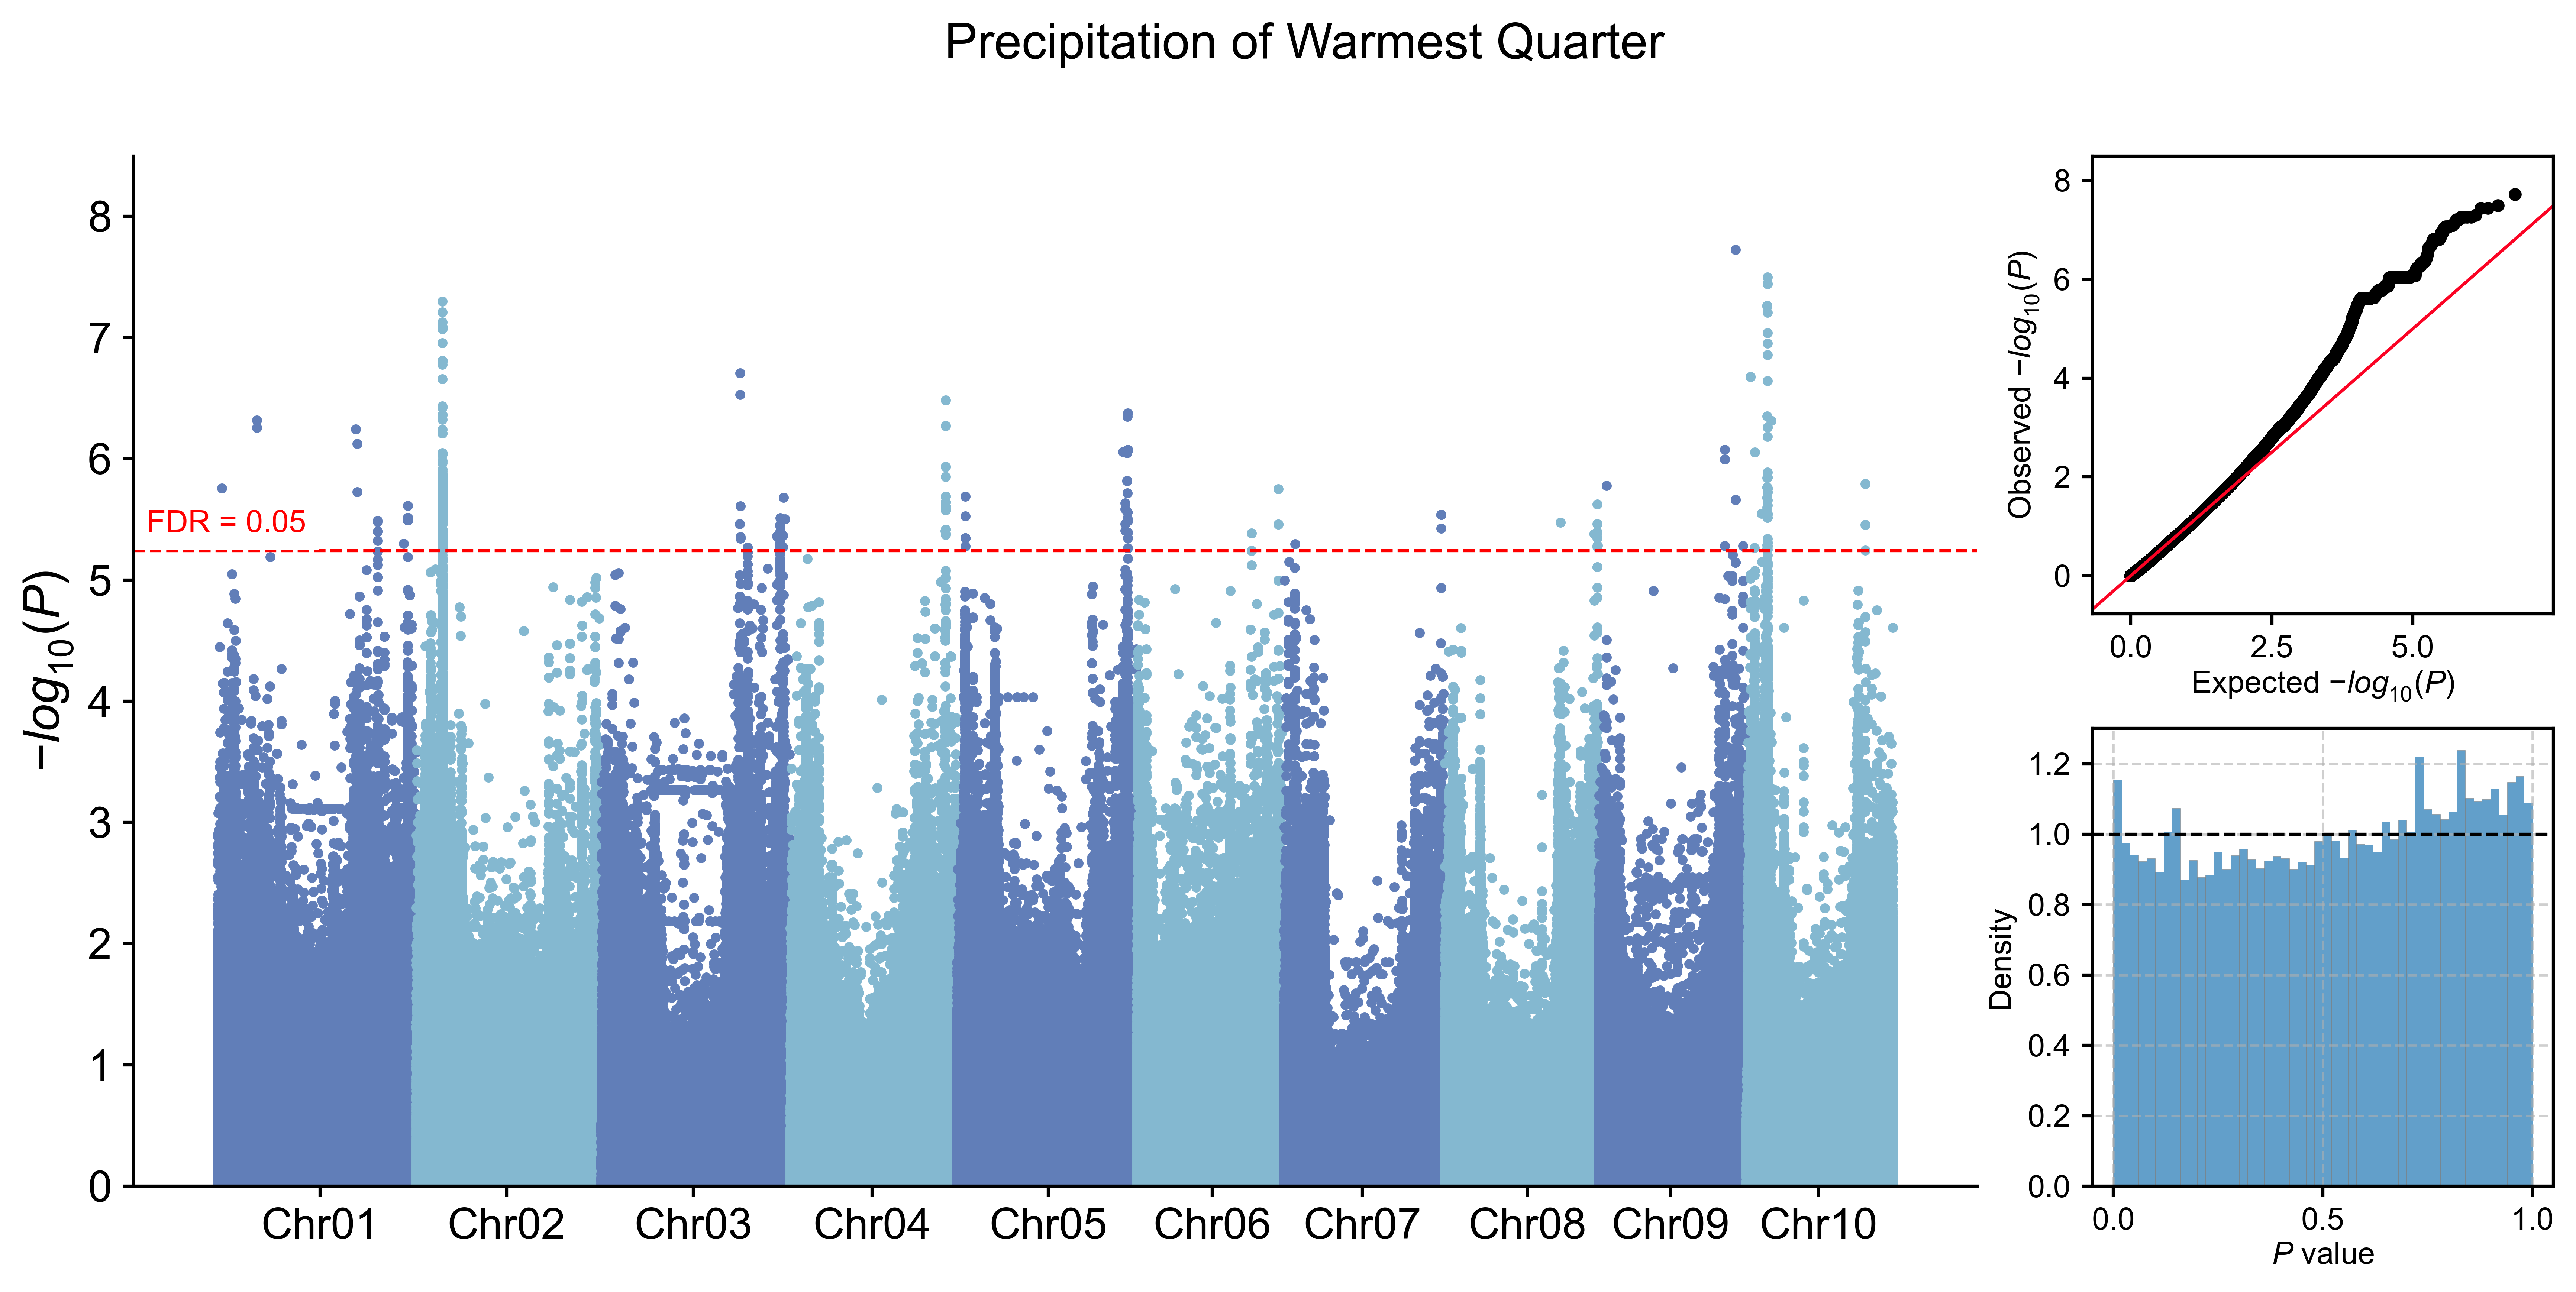

In [ ]:
from IPython.display import Image, display

env_id = 'bio18'
gwas_png = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df_gwas_summary.png'
display(Image(filename=gwas_png, width=1200))

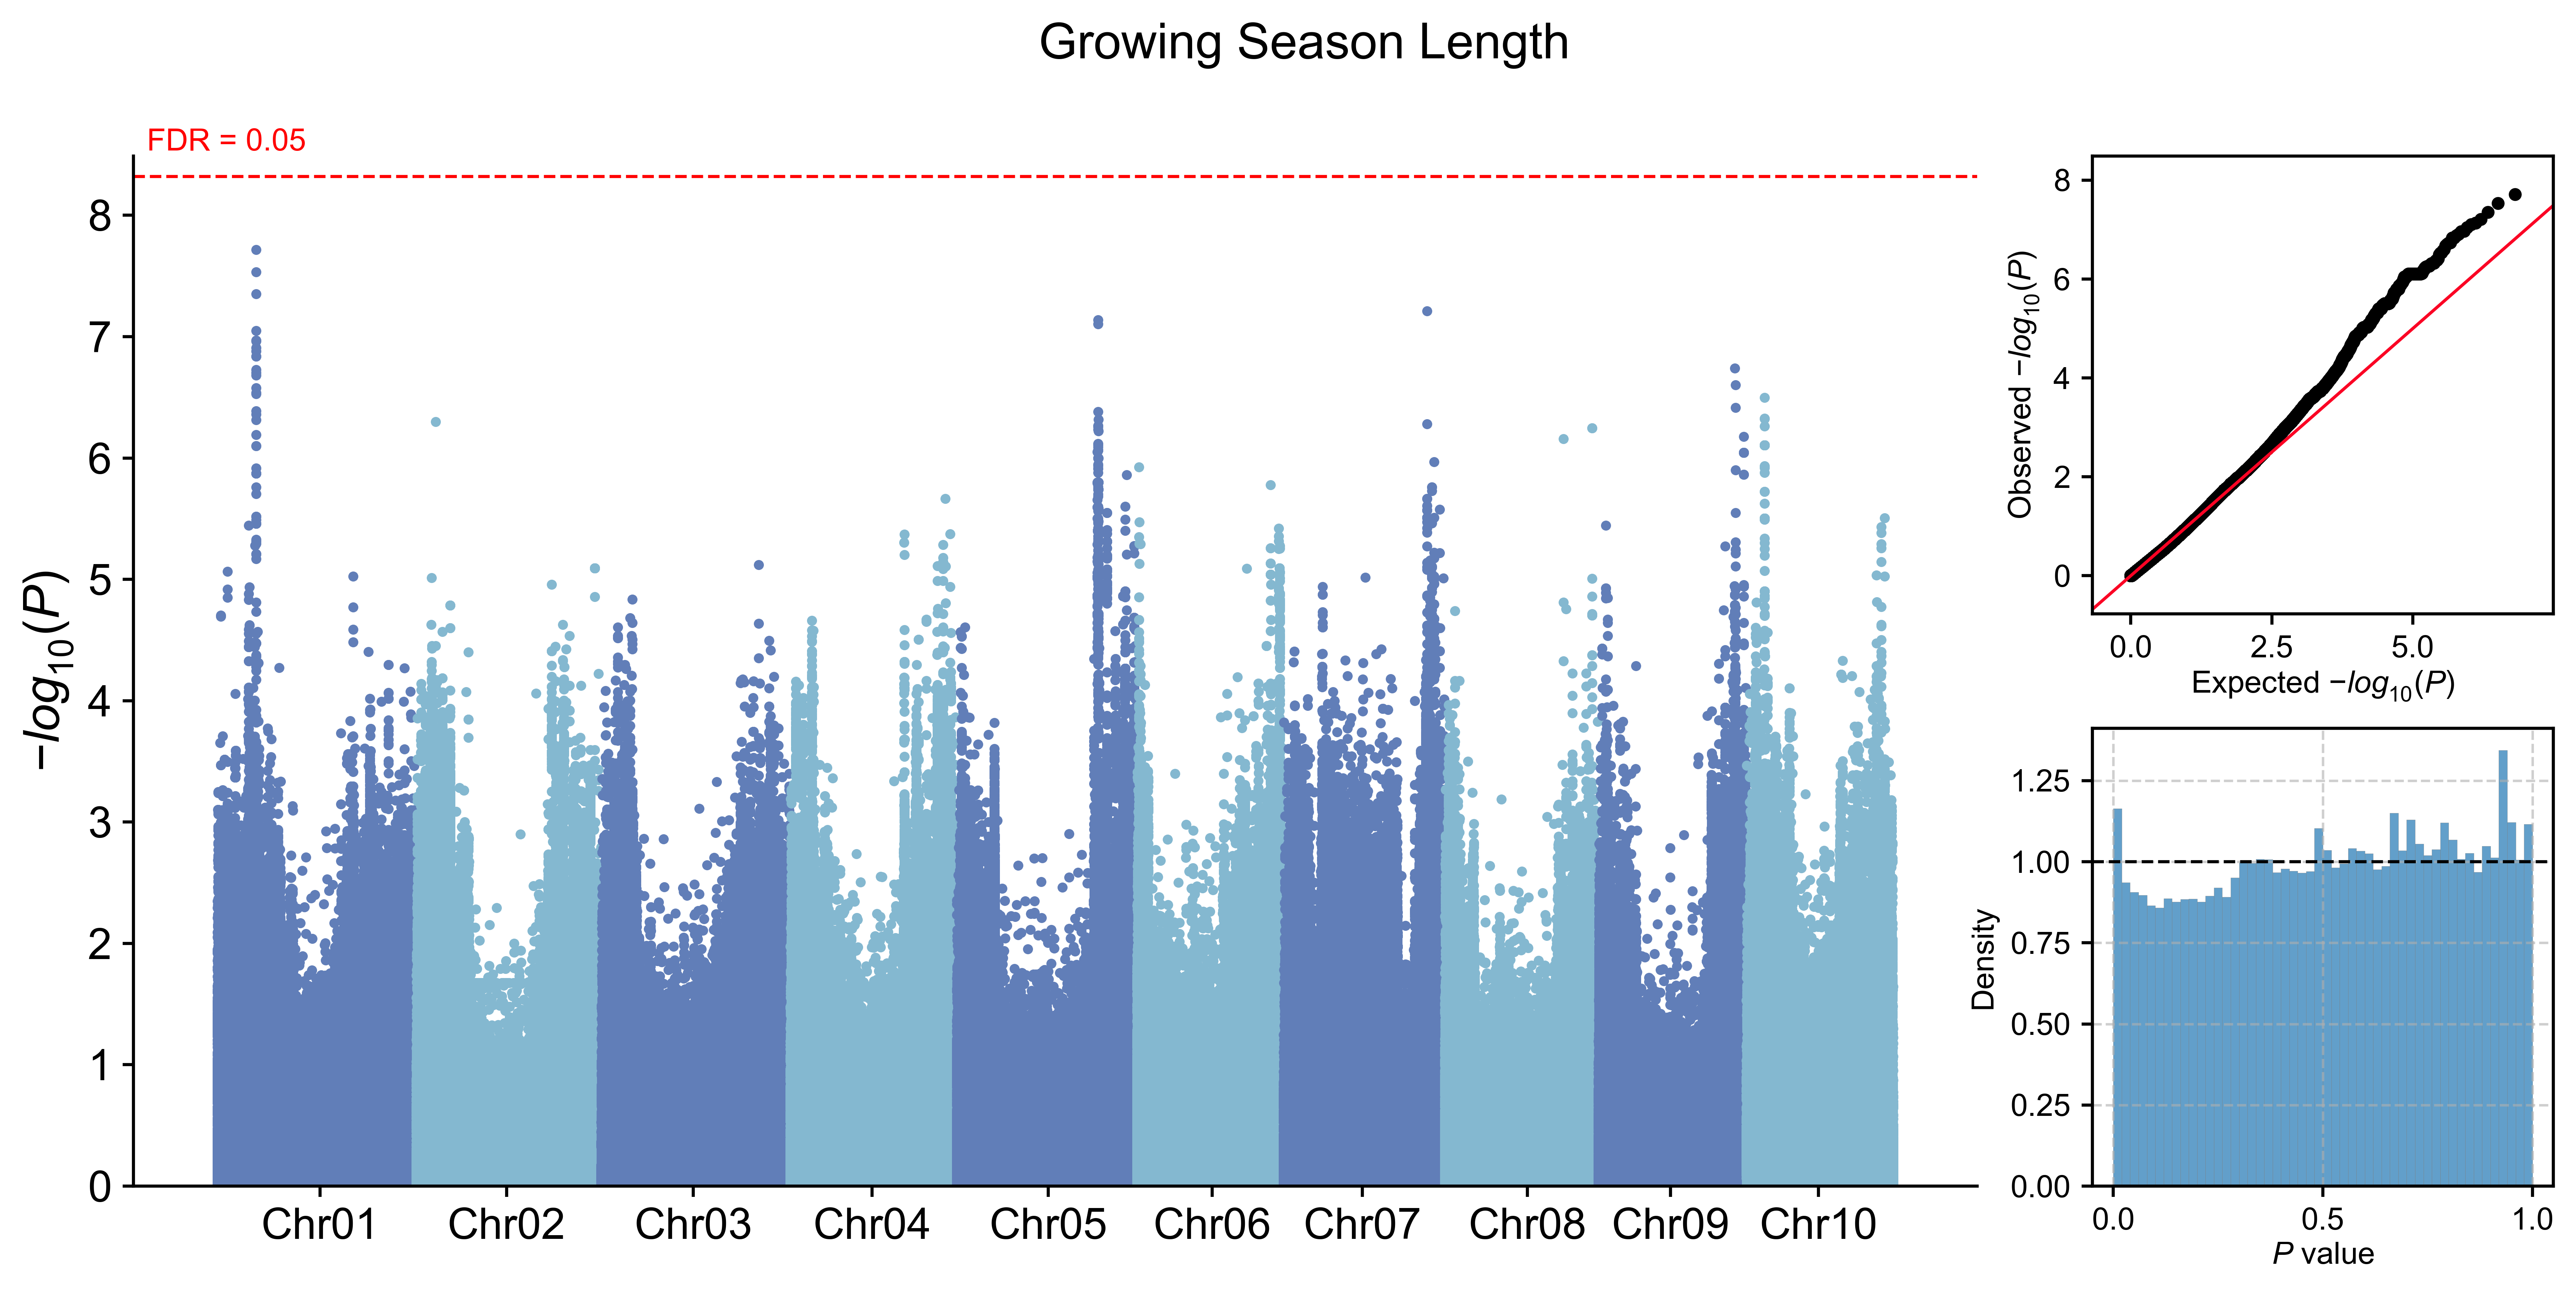

In [ ]:
from IPython.display import Image, display

env_id = 'gsl'
gwas_png = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df_gwas_summary.png'
display(Image(filename=gwas_png, width=1200))

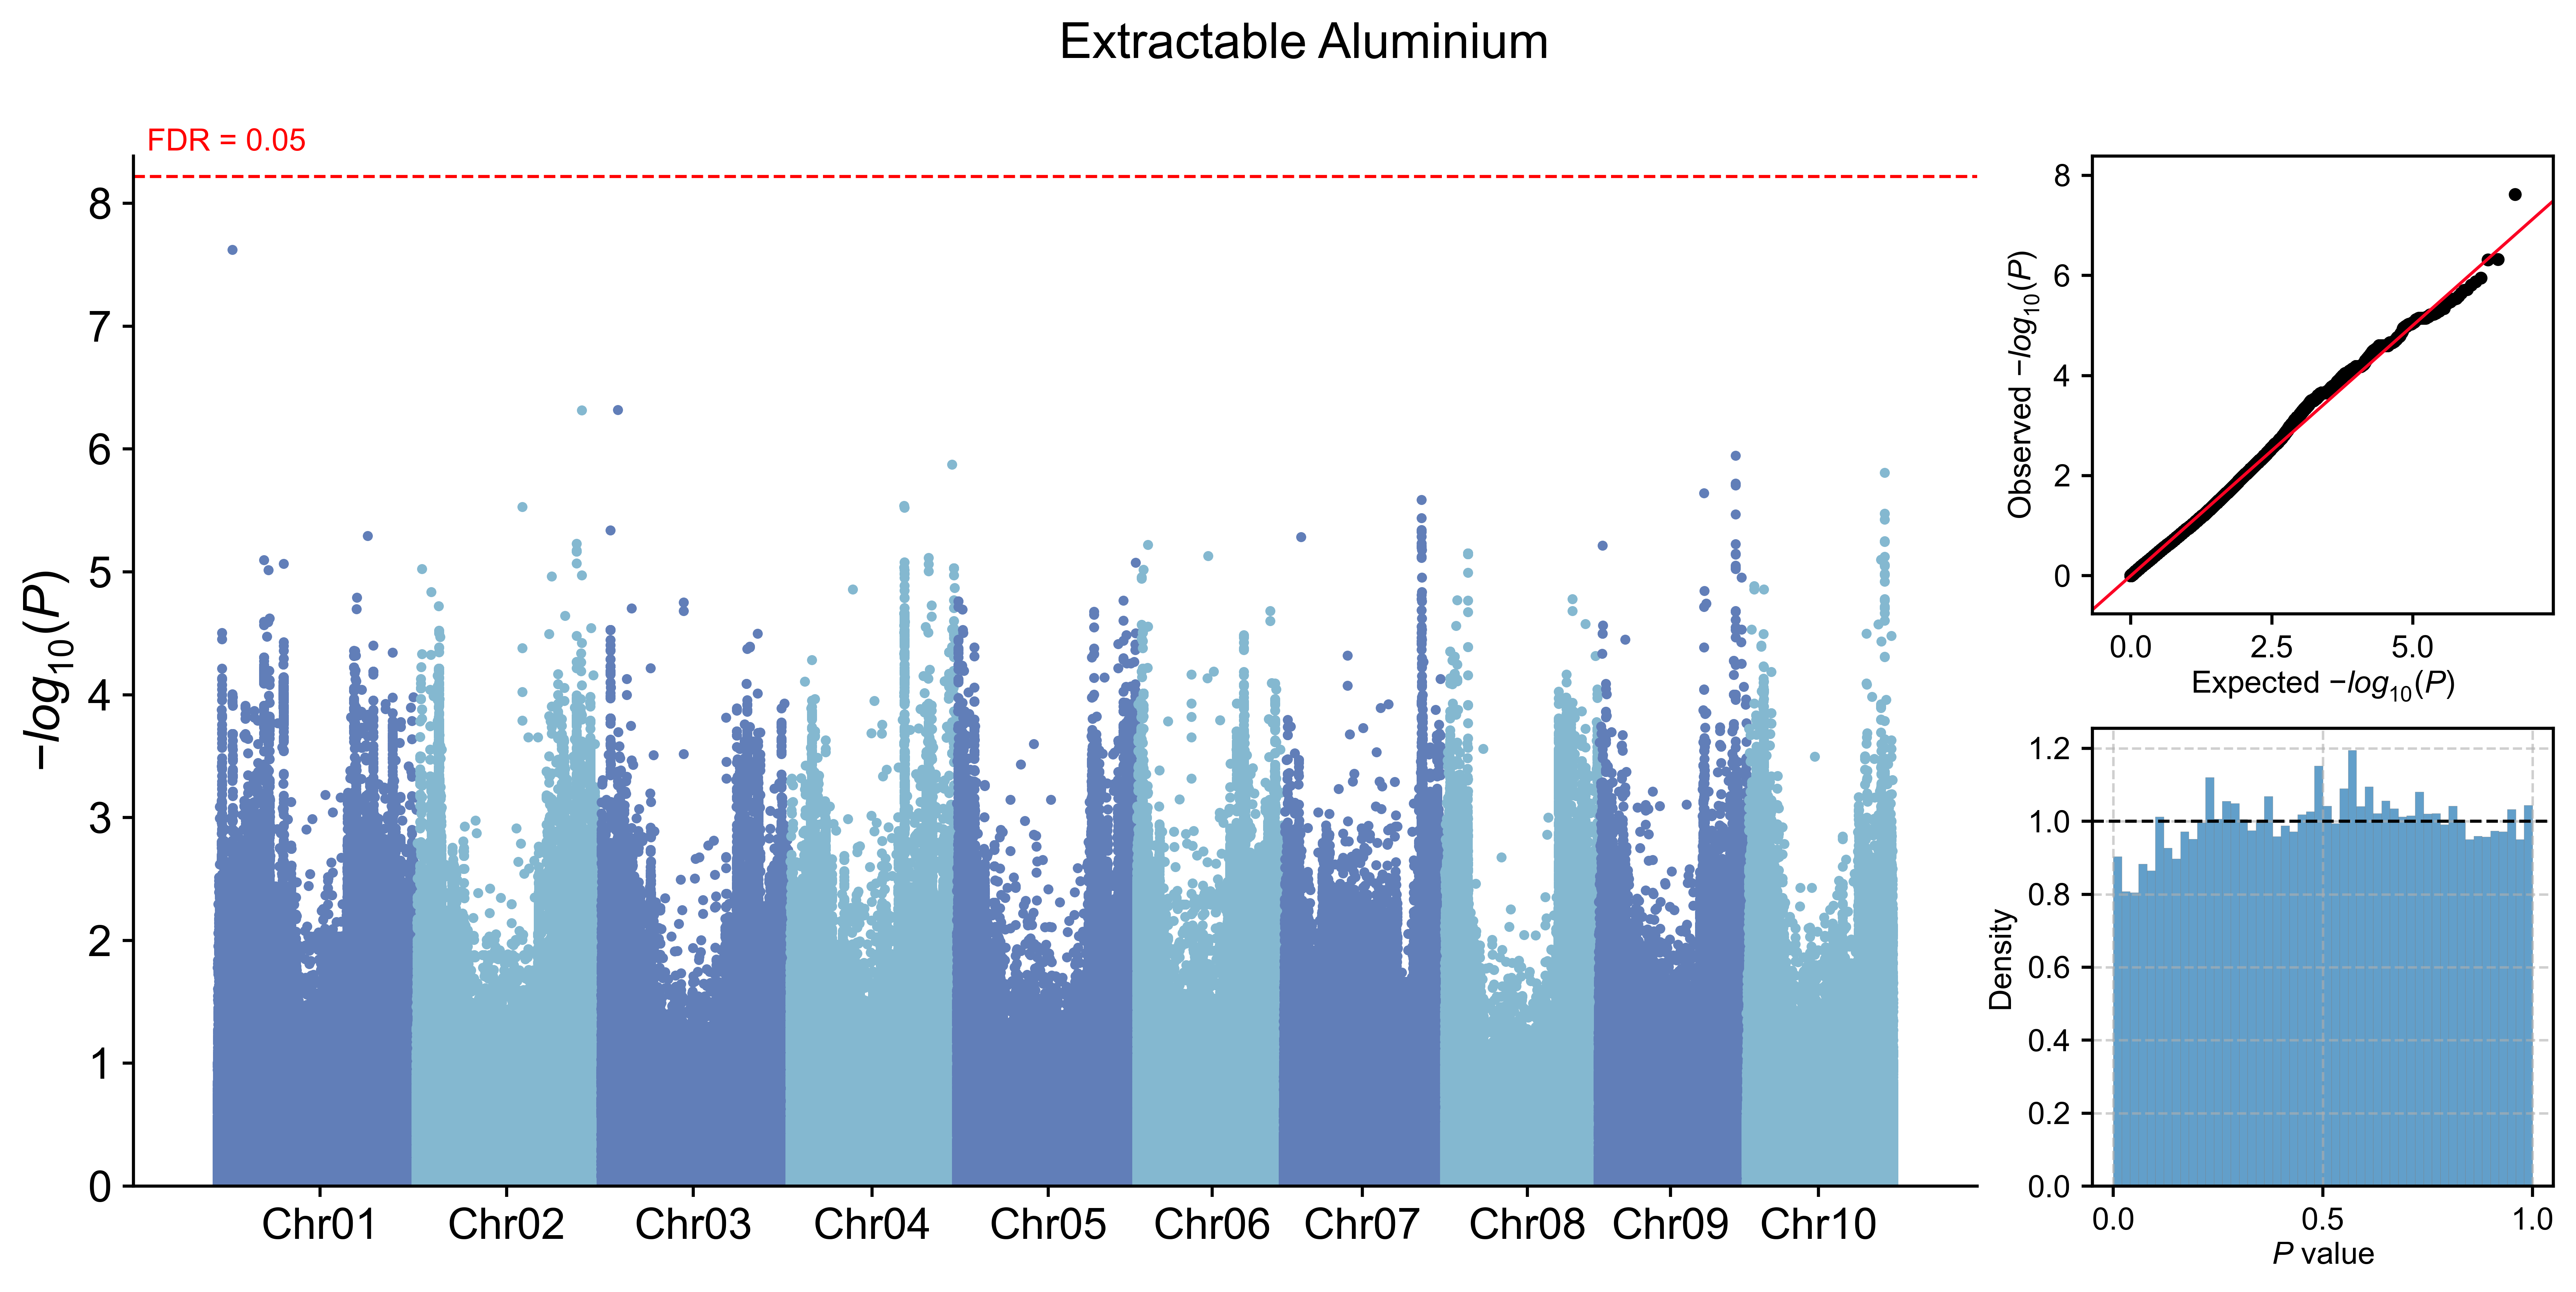

In [ ]:
from IPython.display import Image, display

env_id = 'al'
gwas_png = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df_gwas_summary.png'
display(Image(filename=gwas_png, width=1200))

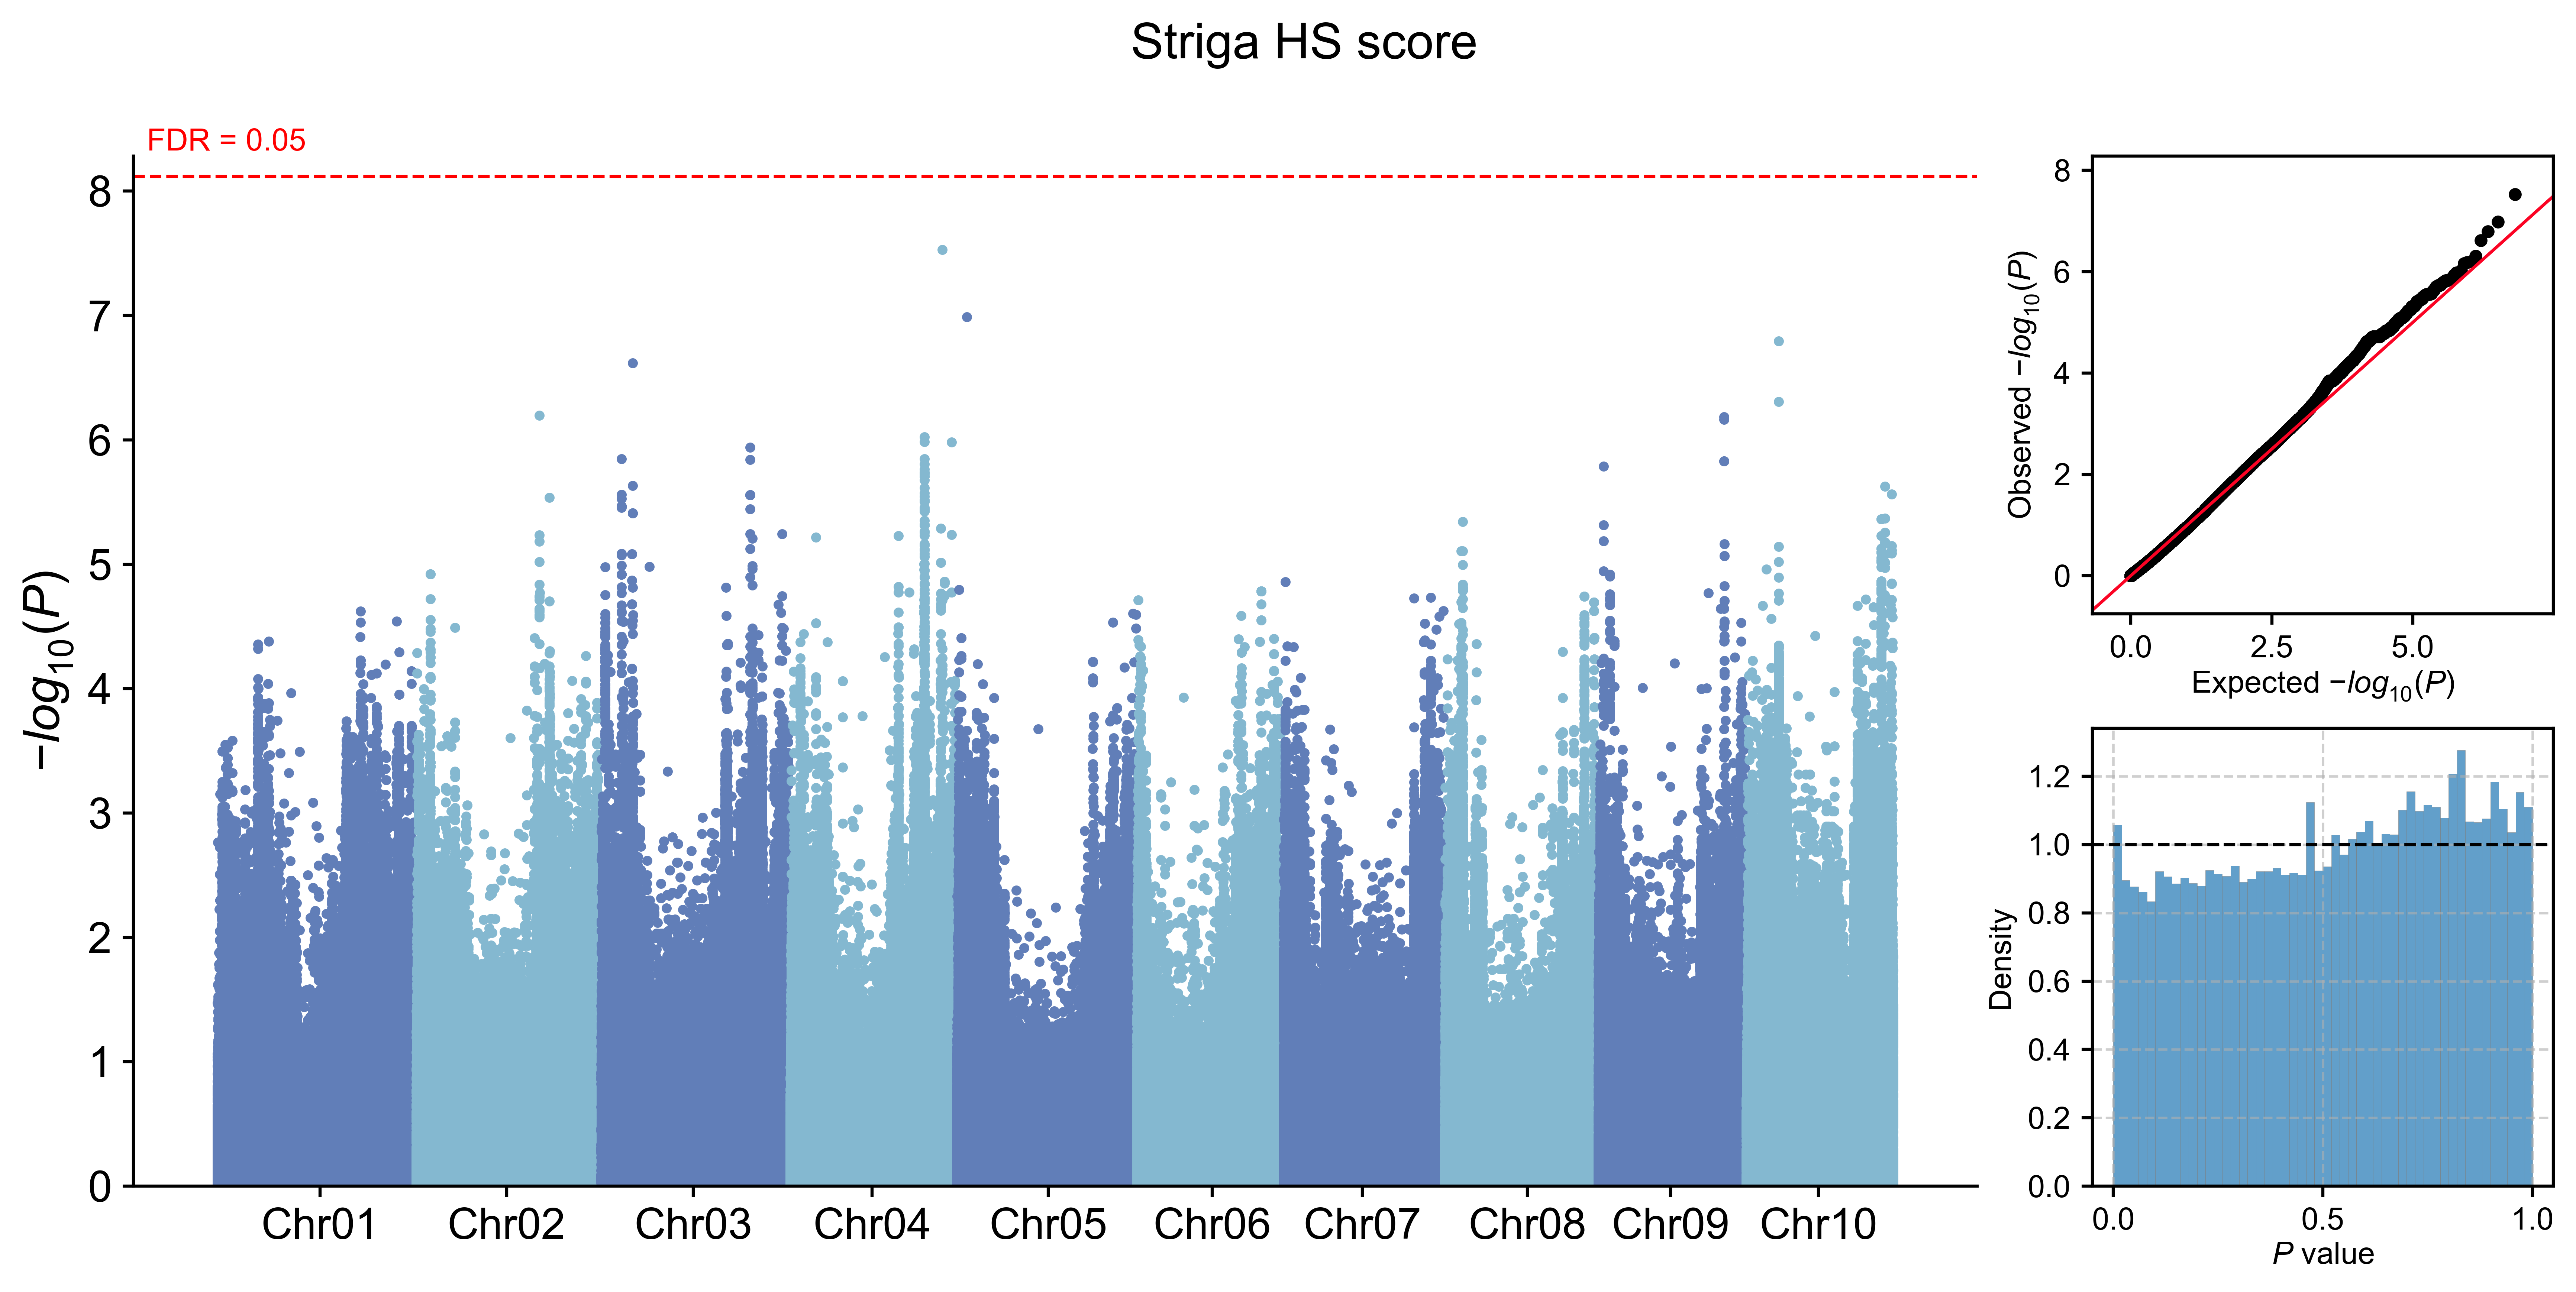

In [ ]:
from IPython.display import Image, display

env_id = 'striga'
gwas_png = f'{gwas_dir}/{env_id}/{env_id}.gemma/{env_id}.gemma.gwas_df_gwas_summary.png'
display(Image(filename=gwas_png, width=1200))